# 2.0 Baseline: Multiclass Linear Classification

Goal: establish a reproducible reference point for a multiclass linear classifier that predicts the full `Emotion_Label`, covering the data pipeline, naive benchmarks, and course-level linear baselines that every later model must beat.

Linear models used include Logistic Regression, Linear SVM. Class-weighted variants are included because the classes are unlikely to be balanced.

## 1. Repository Submission

Repository link: https://github.com/justinseeuoit/machine-learning-course-project.git

## 2. Reproducible Environment

In [1]:
import os, sys, json, random, platform, subprocess, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, label_binarize
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA_DIR, REPORTS_DIR = ROOT / "data", ROOT / "reports"
FIG_DIR = REPORTS_DIR / "figures"
for d in (DATA_DIR, REPORTS_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

env_info = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "seed": SEED}
try:
    env_info["git_commit"] = subprocess.check_output(
        ["git", "rev-parse", "--short", "HEAD"], cwd=ROOT, stderr=subprocess.DEVNULL).decode().strip()
except Exception:
    env_info["git_commit"] = "n/a"
(REPORTS_DIR / "run_metadata.json").write_text(json.dumps(env_info, indent=2))
print(json.dumps(env_info, indent=2))

{
  "python": "3.13.9",
  "platform": "Windows-11-10.0.26300-SP0",
  "numpy": "2.4.4",
  "pandas": "3.0.0",
  "scikit-learn": "1.7.2",
  "seed": 42,
  "git_commit": "c96155d"
}


**Reproducibility checklist:** `pip freeze > requirements` · fixed `SEED` for splits, models and CV · repo-relative paths · `reports/run_metadata.json` written every run (versions + git commit).

In [2]:
DATA_FILE      = "raw_dataset.csv"   
TARGET         = "Emotion_Label"    
DROP_COLS      = ["Track_ID"]
TEST_SIZE      = 0.20
VAL_SIZE       = 0.20
N_SPLITS       = 5

## 3. Working data pipeline

In [3]:
DATA_PATH = DATA_DIR / DATA_FILE
df = pd.read_csv(DATA_PATH)
DATA_SOURCE = str(DATA_PATH.relative_to(ROOT))

print("Data source:", DATA_SOURCE, "| shape:", df.shape)
df.head()
print(df.columns)
print(DROP_COLS)

Data source: data\raw_dataset.csv | shape: (5000, 10)
Index(['Track_ID', 'Genre', 'Tempo', 'Energy', 'Danceability', 'Loudness',
       'Acousticness', 'Instrumentalness', 'Valence', 'Emotion_Label'],
      dtype='str')
['Track_ID']


In [4]:
df = df.drop(columns=DROP_COLS)

n_dupes = df.duplicated().sum()
df = df.drop_duplicates().dropna(subset=[TARGET]).reset_index(drop=True)
n_classes = df[TARGET].nunique()

# Encoding string labels -> integers 0..K-1 while keeping the mapping to decode predictions later
encoder = LabelEncoder()
y = pd.Series(encoder.fit_transform(df[TARGET]), name=TARGET)
class_names = [str(c) for c in encoder.classes_]
K = len(class_names)
X = df.drop(columns=[TARGET])

if y.value_counts().min() < N_SPLITS * 2:
    print('Smallest class has too few rows for the amount of folds.')

quality = pd.DataFrame({"dtype": X.dtypes.astype(str),
                        "missing_%": (X.isna().mean() * 100).round(2),
                        "n_unique": X.nunique()})
print(f"Duplicates removed: {n_dupes} | rows: {len(df)} | features: {X.shape[1]} | classes: {K}")
display(quality)

balance = (pd.DataFrame({"count": y.value_counts().sort_index(),
                         "share": y.value_counts(normalize=True).sort_index().round(3)})
           .rename(index=dict(enumerate(class_names))))
print("Class balance:")
display(balance)

Duplicates removed: 0 | rows: 5000 | features: 8 | classes: 6


,dtype,missing_%,n_unique
Genre,str,0.0,10
Tempo,float64,0.0,4251
Energy,float64,0.0,996
Danceability,float64,0.0,997
Loudness,float64,0.0,3355
Acousticness,float64,0.0,991
Instrumentalness,float64,0.0,993
Valence,float64,0.0,997


Class balance:


,count,share
Emotion_Label,,
angry,832,0.166
calm,864,0.173
energetic,816,0.163
happy,822,0.164
romantic,866,0.173
sad,800,0.160


In [5]:
X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=VAL_SIZE, random_state=SEED, stratify=y_trval)
print(f"train={len(X_train)}  val={len(X_val)}  test={len(X_test)}")

# Every class must appear in every split, otherwise per-class metrics are undefined
for nm, ys in (("train", y_train), ("val", y_val), ("test", y_test)):
    if ys.nunique() != K:
        missing = sorted(set(range(K)) - set(ys.unique()))
        print(f"{nm} split is missing classes: {missing}")
    else:
        print(f"{nm} split contains all {K} classes.")

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]

# Scaling matters for linear models: unscaled features distort regularization and SVM convergence
preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc",  StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh",  OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])

Xt = preprocess.fit(X_train).transform(X_train)
assert Xt.shape[1] == preprocess.transform(X_val).shape[1]
print("Transformed features:", Xt.shape[1], f"(numeric={len(num_cols)}, categorical={len(cat_cols)})")

train=3200  val=800  test=1000
train split contains all 6 classes.
val split contains all 6 classes.
test split contains all 6 classes.
Transformed features: 17 (numeric=7, categorical=1)


## 4. Baseline methodology
Two floors, because one is not enough with K classes:
1. Majority class: always predict the most common emotion (high accuracy if imbalanced, but macro-F1 is tiny since every other class scores 0).
2. Stratified random: guess labels in proportion to the training class frequencies (the "no information in the features" reference).

Any linear model must beat both on macro-F1 and balanced accuracy.

In [6]:
def evaluate(model, X, Y):
    pred = model.predict(X)
    return {"Accuracy":     accuracy_score(Y, pred),
            "Balanced Acc": balanced_accuracy_score(Y, pred),
            "Macro Prec":   precision_score(Y, pred, average="macro", zero_division=0),
            "Macro Recall": recall_score(Y, pred, average="macro", zero_division=0),
            "Macro F1":     f1_score(Y, pred, average="macro", zero_division=0),
            "Weighted F1":  f1_score(Y, pred, average="weighted", zero_division=0)}

PRIMARY = "Macro F1"   # every emotion counts equally, so rare emotions can't be ignored
naive_name   = "Naive (majority class)"
naive2_name  = "Naive (stratified random)"
naive_pipe  = Pipeline([("prep", preprocess),
                        ("model", DummyClassifier(strategy="most_frequent", random_state=SEED))]).fit(X_train, y_train)
naive2_pipe = Pipeline([("prep", preprocess),
                        ("model", DummyClassifier(strategy="stratified", random_state=SEED))]).fit(X_train, y_train)
for nm, p in ((naive_name, naive_pipe), (naive2_name, naive2_pipe)):
    print(nm, "->", {k: round(v, 4) for k, v in evaluate(p, X_val, y_val).items()})

Naive (majority class) -> {'Accuracy': 0.1737, 'Balanced Acc': 0.1667, 'Macro Prec': 0.029, 'Macro Recall': 0.1667, 'Macro F1': 0.0493, 'Weighted F1': 0.0514}
Naive (stratified random) -> {'Accuracy': 0.1638, 'Balanced Acc': 0.1635, 'Macro Prec': 0.1637, 'Macro Recall': 0.1635, 'Macro F1': 0.1635, 'Weighted F1': 0.1636}


## 5. Baseline Table
All models learn one linear score per class, `s_k(x) = w_kᵀx + b_k`, and predict `argmax_k s_k(x)`. They differ in how the K weight vectors are trained:

- Logistic Regression: multinomial softmax, all K vectors fit jointly with cross-entropy (L2-regularised).
- Linear SVM: K one-vs-rest binary problems with hinge loss (L2-regularised).

`class_weight="balanced"` re-weights samples by `n / (K · n_k)`, so rare emotions contribute as much to the loss as common ones. Same preprocessing and the same CV folds for every model.

In [7]:
candidates = {
    "Logistic Regression":            LogisticRegression(C=1.0, max_iter=2000, random_state=SEED),
    "Logistic Regression (balanced)":  LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced", random_state=SEED),
    "Linear SVM":         LinearSVC(C=1.0, dual="auto", max_iter=20000, random_state=SEED),
    "Linear SVM (balanced)": LinearSVC(C=1.0, dual="auto", max_iter=20000, class_weight="balanced", random_state=SEED)}
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
scoring = {"MacroF1": "f1_macro", "Accuracy": "accuracy", "BalAcc": "balanced_accuracy"}

fitted, cv_results = {}, {}
for name, est in candidates.items():
    pipe = Pipeline([("prep", preprocess), ("model", est)])
    cv_results[name] = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring,
                                      return_train_score=True, n_jobs=-1)
    fitted[name] = pipe.fit(X_train, y_train)

for nm, p in ((naive_name, naive_pipe), (naive2_name, naive2_pipe)):
    cv_results[nm] = cross_validate(p, X_train, y_train, cv=cv, scoring=scoring,
                                    return_train_score=True, n_jobs=-1)
    fitted[nm] = p
print("Fitted:", list(fitted))

Fitted: ['Logistic Regression', 'Logistic Regression (balanced)', 'Linear SVM', 'Linear SVM (balanced)', 'Naive (majority class)', 'Naive (stratified random)']


In [8]:
naive_names = [naive_name, naive2_name]
rows = []
for name, pipe in fitted.items():
    r = {"Model": name,
         "CV Macro-F1 (mean)": cv_results[name]["test_MacroF1"].mean(),
         "CV Macro-F1 (std)":  cv_results[name]["test_MacroF1"].std(),
         "Train Macro-F1 (CV)": cv_results[name]["train_MacroF1"].mean()}
    r.update({f"Val {k}": v for k, v in evaluate(pipe, X_val, y_val).items()})
    rows.append(r)

baseline_table = pd.DataFrame(rows).set_index("Model").round(4)

# Select on VALIDATION only; the test set stays untouched until the end
linear_only = baseline_table.drop(index=naive_names)
best_name = linear_only["Val Macro F1"].idxmax()
baseline_table.to_csv(REPORTS_DIR / "baseline_table.csv")
#(REPORTS_DIR / "baseline_table.md").write_text(baseline_table.to_markdown())
print("Best linear baseline (validation Macro-F1):", best_name)
baseline_table

Best linear baseline (validation Macro-F1): Logistic Regression


,CV Macro-F1 (mean),CV Macro-F1 (std),Train Macro-F1 (CV),Val Accuracy,Val Balanced Acc,Val Macro Prec,Val Macro Recall,Val Macro F1,Val Weighted F1
Model,,,,,,,,,
Logistic Regression,0.1644,0.0108,0.2089,0.1650,0.1648,0.1617,0.1648,0.1603,0.1605
Logistic Regression (balanced),0.1625,0.0090,0.2049,0.1575,0.1587,0.1543,0.1587,0.1509,0.1501
Linear SVM,0.1645,0.0095,0.2080,0.1625,0.1623,0.1592,0.1623,0.1579,0.1581
Linear SVM (balanced),0.1626,0.0061,0.2054,0.1550,0.1562,0.1493,0.1562,0.1482,0.1474
Naive (majority class),0.0490,0.0002,0.0492,0.1737,0.1667,0.0290,0.1667,0.0493,0.0514
Naive (stratified random),0.1597,0.0204,0.1704,0.1638,0.1635,0.1637,0.1635,0.1635,0.1636


In [9]:
# One-time final evaluation on the held-out TEST set
test_table = pd.DataFrame({n: evaluate(fitted[n], X_test, y_test)
                           for n in (*naive_names, best_name)}).T.round(4)
test_table.index.name = "Model"
test_table.to_csv(REPORTS_DIR / "test_table.csv")
test_table

,Accuracy,Balanced Acc,Macro Prec,Macro Recall,Macro F1,Weighted F1
Model,,,,,,
Naive (majority class),0.173,0.1667,0.0288,0.1667,0.0492,0.0510
Naive (stratified random),0.166,0.1654,0.1651,0.1654,0.1652,0.1657
Logistic Regression,0.175,0.1748,0.1782,0.1748,0.1742,0.1743


## 6. Discrepancy analysis
Where and why do the numbers disagree? The key extra question is which emotions the model confuses, since a single averaged score can hide classes that are never predicted.

In [10]:
# 6a. Generalisation gaps for the best baseline (Macro-F1)
best_pipe = fitted[best_name]
train_f1 = evaluate(best_pipe, X_train, y_train)["Macro F1"]
cv_f1    = baseline_table.loc[best_name, "CV Macro-F1 (mean)"]
cv_sd    = baseline_table.loc[best_name, "CV Macro-F1 (std)"]
val_f1   = baseline_table.loc[best_name, "Val Macro F1"]
test_f1  = test_table.loc[best_name, "Macro F1"]
naive_f1 = test_table.loc[naive_name, "Macro F1"]
naive2_f1 = test_table.loc[naive2_name, "Macro F1"]

gap = pd.DataFrame({"Macro-F1": [train_f1, cv_f1, val_f1, test_f1, naive_f1, naive2_f1]},
                   index=["Train (refit)", "CV (5-fold)", "Validation", "Test",
                          "Naive majority on Test", "Naive stratified on Test"]).round(4)
display(gap)

print("Train->Test gap        :" + str(train_f1 - test_f1))
if train_f1 - test_f1 > 0.05:
     print('possible overfitting')
else:
       print('small')
print(f"CV->Test gap           :" + str(cv_f1 - test_f1))  
if (abs(cv_f1 - test_f1) > 2*cv_sd):
      print('beyond CV noise')
else:
      print('within CV noise')
print("Lift vs majority naive :" + str(test_f1 - naive_f1))
print("Lift vs stratified     :" + str(test_f1 - naive2_f1))

,Macro-F1
Train (refit),0.2117
CV (5-fold),0.1644
Validation,0.1603
Test,0.1742
Naive majority on Test,0.0492
Naive stratified on Test,0.1652


Train->Test gap        :0.03747959899856726
small
CV->Test gap           :-0.009800000000000003
within CV noise
Lift vs majority naive :0.125
Lift vs stratified     :0.00899999999999998


Logistic Regression: test Macro-F1 = 0.1742  (95% bootstrap CI [0.1493, 0.1991])


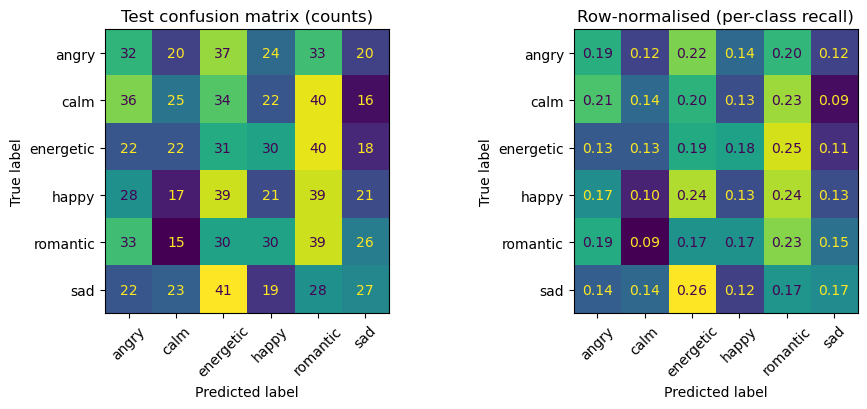

In [11]:
# 6b. Bootstrap 95% CI on test Macro-F1, plus confusion matrices (counts and row-normalised recall)
rng = np.random.default_rng(SEED)
pred_test = best_pipe.predict(X_test)
y_arr = np.asarray(y_test)
boots = []
for i in range(1000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    boots.append(f1_score(y_arr[idx], pred_test[idx], average="macro", zero_division=0))
lo, hi = np.percentile(boots, [2.5, 97.5])
print(f"{best_name}: test Macro-F1 = {test_f1:.4f}  (95% bootstrap CI [{lo:.4f}, {hi:.4f}])")

fig, axes = plt.subplots(1, 2, figsize=(max(9, 1.6 * K), max(4, 0.7 * K)))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=class_names, ax=axes[0],
                                        colorbar=False, xticks_rotation=45)
axes[0].set_title("Test confusion matrix (counts)")
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=class_names, ax=axes[1],
                                        colorbar=False, xticks_rotation=45, normalize="true", values_format=".2f")
axes[1].set_title("Row-normalised (per-class recall)")
plt.tight_layout(); plt.savefig(FIG_DIR / "confusion_matrix.png", dpi=150); plt.show()

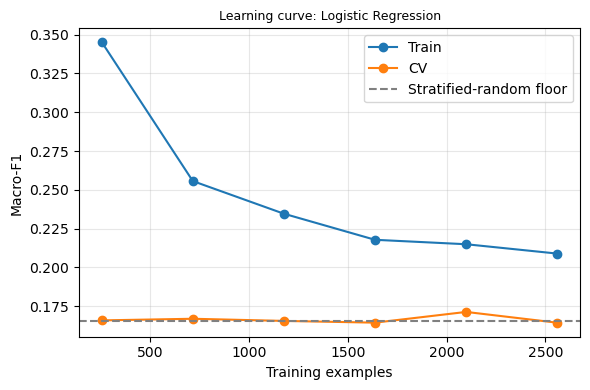

In [12]:
# 6c. Learning curve: variance problem (more data/regularization) or bias problem (features/non-linearity)?
sizes, tr_sc, va_sc = learning_curve(
    Pipeline([("prep", preprocess), ("model", candidates[best_name])]),
    X_train, y_train, cv=cv, scoring="f1_macro",
    train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1, random_state=SEED)
plt.figure(figsize=(6, 4))
plt.plot(sizes, tr_sc.mean(1), "o-", label="Train")
plt.plot(sizes, va_sc.mean(1), "o-", label="CV")
plt.axhline(naive2_f1, color="grey", ls="--", label="Stratified-random floor")
plt.xlabel("Training examples"); plt.ylabel("Macro-F1"); plt.title(f"Learning curve: {best_name}", fontsize=9)
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(FIG_DIR / "learning_curve.png", dpi=150); plt.show()
lc_gap = tr_sc.mean(1)[-1] - va_sc.mean(1)[-1]

,Train Macro-F1,CV Macro-F1
C,,
0.001,0.1581,0.1389
0.010,0.2025,0.1611
0.100,0.2084,0.1614
1.000,0.2089,0.1644
10.000,0.2092,0.1644
100.000,0.2092,0.1644
1000.000,0.2092,0.1644


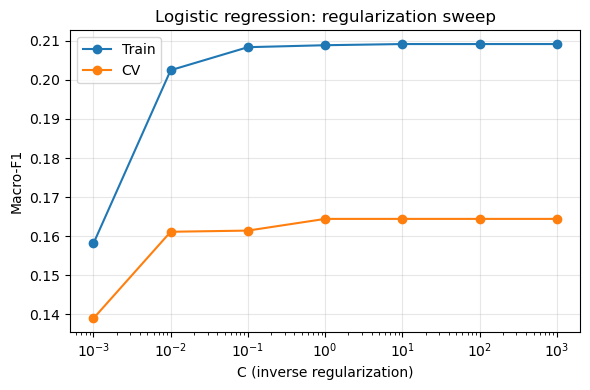

In [13]:
# 6d. Regularization sensitivity (C) for multinomial logistic regression: does the baseline depend on a lucky hyperparameter?
Cs = np.logspace(-3, 3, 7)
rows = []
for C in Cs:
    p = Pipeline([("prep", preprocess), ("model", LogisticRegression(C=C, max_iter=5000, random_state=SEED))])
    r = cross_validate(p, X_train, y_train, cv=cv, scoring="f1_macro", return_train_score=True, n_jobs=-1)
    rows.append((C, r["train_score"].mean(), r["test_score"].mean()))
c_df = pd.DataFrame(rows, columns=["C", "Train Macro-F1", "CV Macro-F1"]).set_index("C").round(4)
display(c_df)
plt.figure(figsize=(6, 4))
plt.semilogx(c_df.index, c_df["Train Macro-F1"], "o-", label="Train")
plt.semilogx(c_df.index, c_df["CV Macro-F1"], "o-", label="CV")
plt.xlabel("C (inverse regularization)"); plt.ylabel("Macro-F1"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Logistic regression: regularization sweep"); plt.tight_layout()
plt.savefig(FIG_DIR / "c_sweep.png", dpi=150); plt.show()

,precision,recall,f1-score,support,pred_share,true_share
happy,0.113,0.092,0.101,131.0,0.132,0.164
calm,0.165,0.101,0.126,138.0,0.106,0.172
sad,0.164,0.141,0.151,128.0,0.138,0.160
angry,0.174,0.188,0.181,133.0,0.180,0.166
romantic,0.175,0.230,0.199,139.0,0.229,0.174
energetic,0.180,0.237,0.205,131.0,0.215,0.164


Classes the model never predicts: none


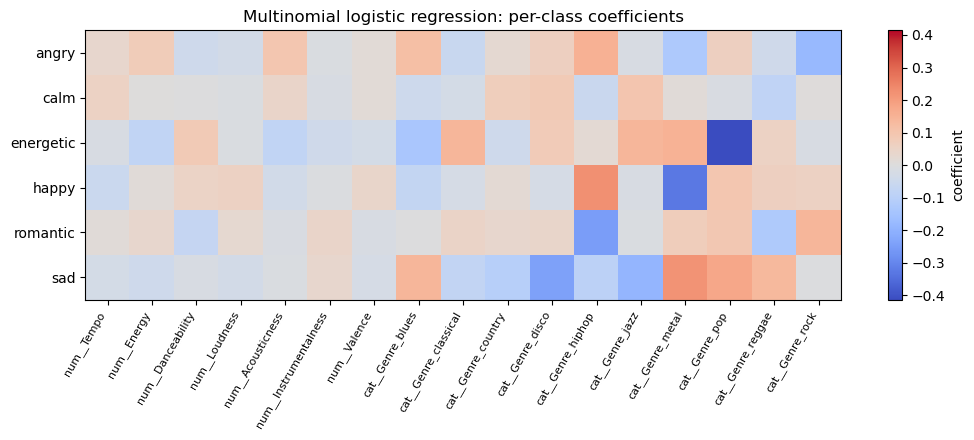

In [14]:
# 6e. Per-class analysis (validation). A single threshold no longer exists, so ask: which emotions are hard?
val_pred = best_pipe.predict(X_val)
report = pd.DataFrame(classification_report(y_val, val_pred, target_names=class_names,
                                            output_dict=True, zero_division=0)).T
per_class = report.loc[class_names, ["precision", "recall", "f1-score", "support"]].round(3)

per_class["pred_share"] = (pd.Series(val_pred).value_counts(normalize=True)
                           .reindex(range(K), fill_value=0).round(3).values)
per_class["true_share"] = (pd.Series(np.asarray(y_val)).value_counts(normalize=True)
                           .reindex(range(K), fill_value=0).round(3).values)
display(per_class.sort_values("f1-score"))
never_predicted = per_class.index[per_class["pred_share"] == 0].tolist()
print("Classes the model never predicts:", never_predicted or "none")
per_class.to_csv(REPORTS_DIR / "per_class_val.csv")

# 6f. Which features drive each emotion? One weight vector per class (standardised, so comparable)
lr_pipe = fitted["Logistic Regression"]
feat_names = lr_pipe.named_steps["prep"].get_feature_names_out()
W = pd.DataFrame(lr_pipe.named_steps["model"].coef_, index=class_names, columns=feat_names)
fig, ax = plt.subplots(figsize=(max(7, 0.5 * len(feat_names) + 2), max(3.5, 0.5 * K + 1.5)))
lim = np.abs(W.values).max()
im = ax.imshow(W.values, cmap="coolwarm", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(feat_names))); ax.set_xticklabels(feat_names, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(K)); ax.set_yticklabels(class_names)
fig.colorbar(im, ax=ax, label="coefficient"); ax.set_title("Multinomial logistic regression: per-class coefficients")
plt.tight_layout(); plt.savefig(FIG_DIR / "coefficients.png", dpi=150); plt.show()

In [15]:
# 6g. Auto-generated discrepancy summary (rewrite in your own words for the memo)
shares = y.value_counts(normalize=True)
findings = [
    f"Best linear baseline: {best_name}; test Macro-F1 = {test_f1:.4f}, 95% CI [{lo:.4f}, {hi:.4f}] "
    f"(accuracy {test_table.loc[best_name, 'Accuracy']:.3f}, balanced accuracy {test_table.loc[best_name, 'Balanced Acc']:.3f}).",
    f"Lift over naive floors (Macro-F1): {test_f1 - naive_f1:+.4f} vs majority class, {test_f1 - naive2_f1:+.4f} vs stratified random "
    f"(chance accuracy with {K} classes = {1/K:.3f}).",
    f"Train vs test gap {train_f1 - test_f1:+.4f}; CV vs test gap {cv_f1 - test_f1:+.4f}.",
    f"Learning-curve train/CV gap at full data: {lc_gap:.4f} "
    f"({'variance-limited: regularise / add data' if lc_gap > 0.05 else 'bias-limited: richer features or a non-linear model may help'}).",
    f"Class-weighting effect on validation Macro-F1: "
    f"LR {baseline_table.loc['Logistic Regression', 'Val Macro F1']:.4f} -> {baseline_table.loc['Logistic Regression (balanced)', 'Val Macro F1']:.4f}; "
    f"SVM {baseline_table.loc['Linear SVM', 'Val Macro F1']:.4f} -> {baseline_table.loc['Linear SVM (balanced)', 'Val Macro F1']:.4f}.",
    f"Hardest class on validation (lowest F1): {per_class['f1-score'].idxmin()} (F1={per_class['f1-score'].min():.3f}); "
    f"easiest: {per_class['f1-score'].idxmax()} (F1={per_class['f1-score'].max():.3f}). Never predicted: {never_predicted or 'none'}.",
]
if shares.max() > 0.3 or shares.max() / shares.min() > 2:
    findings.append(f"Class imbalance (largest {shares.max():.0%}, smallest {shares.min():.0%}): accuracy is misleading; report Macro-F1, balanced accuracy and per-class recall.")
for f in findings:
    print("-", f)

- Best linear baseline: Logistic Regression; test Macro-F1 = 0.1742, 95% CI [0.1493, 0.1991] (accuracy 0.175, balanced accuracy 0.175).
- Lift over naive floors (Macro-F1): +0.1250 vs majority class, +0.0090 vs stratified random (chance accuracy with 6 classes = 0.167).
- Train vs test gap +0.0375; CV vs test gap -0.0098.
- Learning-curve train/CV gap at full data: 0.0446 (bias-limited: richer features or a non-linear model may help).
- Class-weighting effect on validation Macro-F1: LR 0.1603 -> 0.1509; SVM 0.1579 -> 0.1482.
- Hardest class on validation (lowest F1): happy (F1=0.101); easiest: energetic (F1=0.205). Never predicted: none.


### Discrepancy write-up

**Summary:** The best linear baseline (Logistic Regression) reaches a test Macro-F1 of 0.1742, against 0.1652 for random guessing and 0.0492 for the majority class. The 95% bootstrap CI [0.149, 0.199] contains the random-guess score. The model is not overfitting, so the features appear to carry little linear signal for `Emotion_Label`.

| Discrepancy observed | Likely cause | Evidence | Fix / next test |
|---|---|---|---|
| Linear models barely beat random guessing | Weak or non-linear relationship between the features and the emotion label | Test Macro-F1 0.1742 vs 0.1652 floor; CI [0.149, 0.199] contains the floor. On validation tests, LR (0.160) is below the random floor (0.1635). | Try using a non-linear model (random forest, etc.) on the same pipeline and add feature interactions |
| Large lift over the majority-class floor (means little) | The majority floor is weak by design: it predicts one class, so Macro-F1 is only about 0.05 | Lift +0.125 compared to majority, but only +0.009 comapared to stratified random | Use stratified random as the main floor |
| Train score is only slightly above test (not overfitting) | The model is bias-limited | Train 0.212 vs test 0.174 (gap +0.037, under the 0.05 threshold) with learning-curve gap 0.045 | More data won't help, so try a non-linear model |
| Class weighting lowers the score | Classes are nearly balanced (16.0 - 17.3%), so reweighting adds noise rather than fixing a skew | Val Macro-F1: LR 0.160 -> 0.151, SVM 0.158 -> 0.148 | Not needed for this dataset |
| Regularization doesn't help | C isn't the bottleneck | CV Macro-F1 is flat at 0.1644 for C >= 1; at C = 0.001 it falls to 0.139 (over-regularized) | Revisit features instead of tuning C |
| LR and SVM perform similarly | Both fit linear boundaries and hit the same ceiling | CV 0.1644 vs 0.1645 | Compare against a non-linear model |
| Happy and calm are hardest, while energetic and romantic score best | This is most likely noise | Val F1: happy 0.101, calm 0.126 vs energetic 0.205, romantic 0.199; only about 130 rows per class. Happy and calm are under-predicted (13% and 11% vs 16 - 17% share), energetic and romantic over-predicted (22% and 23%). | Check with repeated CV; look at the test confusion matrix |

**Conclusion:** This baseline is the reference that later models must beat. The most useful next step is a non-linear model (such as random forest) on the same split. If that also lands near 0.17, the features likely contain little information about the labels.

## 8. Start / Stop / Continue plan

**Start**
- [ ] Tuning C (and `class_weight`) with nested CV or a fixed validation split
- [ ] Inspecting per-class precision/recall and the confusion matrix before trusting any averaged score
- [ ] Feature engineering / interaction terms where the linear boundary underfits
- [ ] Logging each run (config + metrics) to a CSV
- [ ] Trying a hierarchical or merged-label view if some emotions are inseparable (e.g. group into valence/arousal quadrants)

**Stop**
- [ ] Touching the test set during model selection
- [ ] Comparing models on different splits or preprocessing
- [ ] Reporting accuracy alone when classes are imbalanced
- [ ] Creating label-derived columns (like `is_happy`) inside the feature table
- [ ] Untracked environment changes (always update `requirements.txt`)

**Continue**
- [ ] Fixed seeds and the split-first-then-preprocess pipeline
- [ ] Naive benchmarks as the reference for every new model
- [ ] Auto-saving tables and figures to `reports/`
- [ ] Git tags per milestone (e.g. `v0.1-baseline`)

In [16]:
print("Saved:", sorted(p.name for p in REPORTS_DIR.iterdir() if p.is_file()), "| figures:", sorted(p.name for p in FIG_DIR.iterdir()))

Saved: ['baseline_table.csv', 'baseline_table.md', 'per_class_val.csv', 'run_metadata.json', 'test_table.csv'] | figures: ['c_sweep.png', 'coefficients.png', 'confusion_matrix.png', 'learning_curve.png']
